## Inspect Missing Values in Ames Housing Dataset

In [1]:
from pathlib import Path
import pandas as pd

# Locate the Ames Housing dataset CSV file
csv_path = Path("data/train.csv")

if not csv_path.exists():
    csv_path = Path("../data/train.csv")

# Load the dataset
df = pd.read_csv(
    csv_path,
    keep_default_na=False,
    na_values=["NA", ""]
)

# Verify masonry veneer values
print("Missing MasVnrType:", df["MasVnrType"].isna().sum())
print("None category:", (df["MasVnrType"] == "None").sum())

print(
    "None with positive area:",
    ((df["MasVnrType"] == "None") & (df["MasVnrArea"] > 0)).sum()
)

print("Missing MasVnrArea:", df["MasVnrArea"].isna().sum())

# Count missing values in each column
missing_count = df.isna().sum()

# Calculate missing percentages
missing_percent = (missing_count / len(df)) * 100

# Create a missing-value report
missing_report = pd.DataFrame({
    "Missing" : missing_count,
    "Missing (%)": missing_percent
}).sort_values(by="Missing", ascending=False)

print("Dataset shape:", df.shape)

# Display the 15 columns with the most missing values
display(missing_report[missing_report["Missing"] > 0].head(15))

Missing MasVnrType: 8
None category: 864
None with positive area: 5
Missing MasVnrArea: 8
Dataset shape: (1460, 81)


,Missing,Missing (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageFinish,81,5.547945
GarageQual,81,5.547945
GarageYrBlt,81,5.547945
GarageType,81,5.547945


## Investigate if PoolQC is Missing When PoolArea is Zero

In [2]:
# Identify missing pool quality values
missing_pool = df["PoolQC"].isna()

# Identify houses with zero pool area
no_pool_area = df["PoolArea"] == 0

# Count houses satisfying both conditions
matched = (missing_pool & no_pool_area).sum()

print("Missing PoolQC:", missing_pool.sum())
print("Missing PoolQC and PoolArea == 0:", matched)

# Calculate the percentage of matching observations
percentage = (matched / missing_pool.sum()) * 100

print(f"Matching percentage: {percentage:.2f}%")

Missing PoolQC: 1453
Missing PoolQC and PoolArea == 0: 1453
Matching percentage: 100.00%


## Investigate GarageType Mismatches and Missing Values

In [3]:
# Identify missing garage type
missing_garage = df["GarageType"].isna()

# Identify houses with zero garage area
no_garage_area = df["GarageArea"] == 0

# Count matching conditions
matched_garage = (missing_garage & no_garage_area).sum()

# Find rows where the conditions disagree
mismatches = (missing_garage != no_garage_area).sum()

print("Missing GarageType:", missing_garage.sum())
print("Zero GarageArea:", no_garage_area.sum())
print("Both conditions:", matched_garage)
print("Mismatches:", mismatches)

Missing GarageType: 81
Zero GarageArea: 81
Both conditions: 81
Mismatches: 0


## Investigate MiscFeature Missing Values

In [4]:
# Check for missing miscellaneous features
missing_misc = df["MiscFeature"].isna()

# Check for zero miscellaneous feature value
zero_misc_value = df["MiscVal"] == 0

# Compare both conditions
comparison = pd.crosstab(
    missing_misc,
    zero_misc_value,
    rownames=["MiscFeature Missing"],
    colnames=["MiscVal is Zero"]
)

# Find houses with a miscellaneous feature but a zero value
unusual_misc = df.loc[
    df["MiscFeature"].notna() & (df["MiscVal"] == 0),
    ["Id", "MiscFeature", "MiscVal"]
]

display(comparison)
display(unusual_misc)

# Count inconsistencies
mismatches = (missing_misc != zero_misc_value).sum()

print("Mismatches:", mismatches)

MiscVal is Zero,False,True
MiscFeature Missing,,
False,52,2
True,0,1406


,Id,MiscFeature,MiscVal
873,874,Othr,0
1200,1201,Shed,0


Mismatches: 2


## Categorizing the Remaining Missing Values

In [5]:
# Identify columns containing missing values
missing_cols = df.columns[df.isna().any()]

# Select only columns with missing values
missing_df = df[missing_cols]

# Separate missing columns by data type
numeric_missing = missing_df.select_dtypes(
    include=['number']
).columns.tolist()

categorical_missing = missing_df.select_dtypes(
    exclude=['number']
).columns.tolist()

print("Numerical features with missing values")
print(numeric_missing)

print("\nCategorical features with missing values:")
print(categorical_missing)

print("\nTotal:", len(missing_cols))

Numerical features with missing values
['LotFrontage', 'MasVnrArea', 'GarageYrBlt']

Categorical features with missing values:
['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']

Total: 19


## Investigate MasVnrType and MasVnrArea Missing Values

In [6]:
# Identify missing masonry veneer type
missing_type = df["MasVnrType"].isna()

# Check related masonry veneer area
area_zero = df["MasVnrArea"] == 0
area_positive = df["MasVnrArea"] > 0
area_missing = df["MasVnrArea"].isna()

print("Missing MasVnrType:", missing_type.sum())

print("Missing type + Zero area:",
      (missing_type & area_zero).sum())

print("Missing type + Positive area:",
      (missing_type & area_positive).sum())

print("Missing type + Missing area:",
      (missing_type & area_missing).sum())

Missing MasVnrType: 8
Missing type + Zero area: 0
Missing type + Positive area: 0
Missing type + Missing area: 8


## Verify the Raw Masonry Values

In [7]:
# Reload the CSV without automatic missing value conversion
raw_df = pd.read_csv(csv_path, keep_default_na=False)

# Inspect original values that pandas interpreted as missing
print("Original masonry type values:")
print(
    raw_df.loc[missing_type, "MasVnrType"].value_counts(dropna=False)
)

# Inspect the 13 unusual observations
unusual_rows = missing_type &  (area_positive | area_missing)

display(
    raw_df.loc[
        unusual_rows,
        ["Id", "MasVnrType", "MasVnrArea"]
    ]
)

Original masonry type values:
MasVnrType
NA    8
Name: count, dtype: int64


,Id,MasVnrType,MasVnrArea
234,235,NA,NA
529,530,NA,NA
650,651,NA,NA
936,937,NA,NA
973,974,NA,NA
977,978,NA,NA
1243,1244,NA,NA
1278,1279,NA,NA


## Investigate Basement Features with Missing Values

In [8]:
# Basement-related categorical features
basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

# Identify houses with no recorded basement area
no_basement = df["TotalBsmtSF"] == 0

print("Houses with zero basement area:", no_basement.sum())

# Investigate missing basement information
for col in basement_cols:
    missing = df[col].isna()

    print(f"\n{col}")
    print("Total missing:", missing.sum())
    print("Missing + No basement:", (missing & no_basement).sum())
    print("Missing + Has basement:", (missing & ~no_basement).sum())

Houses with zero basement area: 37

BsmtQual
Total missing: 37
Missing + No basement: 37
Missing + Has basement: 0

BsmtCond
Total missing: 37
Missing + No basement: 37
Missing + Has basement: 0

BsmtExposure
Total missing: 38
Missing + No basement: 37
Missing + Has basement: 1

BsmtFinType1
Total missing: 37
Missing + No basement: 37
Missing + Has basement: 0

BsmtFinType2
Total missing: 38
Missing + No basement: 37
Missing + Has basement: 1


## Inspect the Basement Exceptions

In [9]:
# Select houses with a basement but missing related information
basement_exceptions = df.loc[
    (df["TotalBsmtSF"] > 0) &
    (
        df["BsmtExposure"].isna() |
        df["BsmtFinType2"].isna()
    ),
    [
        "Id",
        "TotalBsmtSF",
        "BsmtExposure",
        "BsmtFinType1",
        "BsmtFinType2",
        "BsmtFinSF1",
        "BsmtFinSF2"
    ]
]

display(basement_exceptions)

,Id,TotalBsmtSF,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2
332,333,3206,No,GLQ,NaN,1124,479
948,949,936,NaN,Unf,Unf,0,0


## Investigate the Actual Basement Exposure

In [10]:
# Count the different basement exposure categories
exposure_counts = df["BsmtExposure"].value_counts(
    dropna=False
)

display(exposure_counts)

BsmtExposure
No     953
Av     221
Gd     134
Mn     114
NaN     38
Name: count, dtype: int64

## Cleaning Basement Missing Values

In [11]:
# Preserve the original dataset
df_clean = df.copy()

# Identify houses without basements
no_basement = df_clean["TotalBsmtSF"] == 0

# Clean basement categorical features
for col in basement_cols:

    # Structural absence: No basement exists
    df_clean.loc[
        no_basement & df_clean[col].isna(),
        col
    ] = "No Basement"

    # Unknown information: Basement exists
    df_clean.loc[
        ~no_basement & df_clean[col].isna(),
        col
    ] = "Unknown"

# Verify remaining missing values
print(df_clean[basement_cols].isna().sum())

# Inspect the two previously identified anomalies
display(
    df_clean.loc[
        df_clean["Id"].isin([333, 949]),
        ["Id", "TotalBsmtSF", "BsmtExposure", "BsmtFinType2"]
    ]
)

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64


,Id,TotalBsmtSF,BsmtExposure,BsmtFinType2
332,333,3206,No,Unknown
948,949,936,Unknown,Unf


## Cleaning Garage Missing Values

In [12]:
# Garage related categorical features
garage_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

# Identify houses without garages
no_garage = df_clean["GarageArea"] == 0

# Clean garage categorical features
for col in garage_cols:

    # House has no garage
    df_clean.loc[
        no_garage & df_clean[col].isna(),
        col
    ] = "NoGarage"

    # House has a garage, but information is missing
    df_clean.loc[
        ~no_garage & df_clean[col].isna(),
        col
    ] = "Unknown"

# Verify cleaning results
print("Remaining missing garage categories:")
print(df_clean[garage_cols].isna().sum())

print("\nMissing garage construction years:")
print(df_clean["GarageYrBlt"].isna().sum())

Remaining missing garage categories:
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64

Missing garage construction years:
81


## Cleaning Other Structural Missing Values

In [13]:
# Map structural features to meaningful absence labels
structural_cols = {
    "PoolQC": "NoPool",
    "Fence": "NoFence",
    "Alley": "NoAlley",
    "FireplaceQu": "NoFireplace",
    "MiscFeature": "NoMisc"
}

# Replace structural missing values
for col, label in structural_cols.items():
    df_clean[col] = df_clean[col].fillna(label)

# Verify the cleaning results
print("Remaining missing values:")
print(df_clean[list(structural_cols)].isna().sum())

# Inspect the resulting categories
for col in structural_cols:
    print(f"\n{col}")
    print(df_clean[col].value_counts())

Remaining missing values:
PoolQC         0
Fence          0
Alley          0
FireplaceQu    0
MiscFeature    0
dtype: int64

PoolQC
PoolQC
NoPool    1453
Gd           3
Ex           2
Fa           2
Name: count, dtype: int64

Fence
Fence
NoFence    1179
MnPrv       157
GdPrv        59
GdWo         54
MnWw         11
Name: count, dtype: int64

Alley
Alley
NoAlley    1369
Grvl         50
Pave         41
Name: count, dtype: int64

FireplaceQu
FireplaceQu
NoFireplace    690
Gd             380
TA             313
Fa              33
Ex              24
Po              20
Name: count, dtype: int64

MiscFeature
MiscFeature
NoMisc    1406
Shed        49
Gar2         2
Othr         2
TenC         1
Name: count, dtype: int64


## Investigate Electrical Missing Values

In [14]:
# Inspect electrical system categories
electrical_counts = df_clean["Electrical"].value_counts(
    dropna=False
)

print("Electrical system distribution:")
print(electrical_counts)

# Identify houses with missing electrical information
missing_electrical = df_clean["Electrical"].isna()

print("\nHouses with missing Electrical:")
display(
    df_clean.loc[
        missing_electrical,
        ["Id", "YearBuilt", "Electrical"]
    ]
)

Electrical system distribution:
Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64

Houses with missing Electrical:


,Id,YearBuilt,Electrical
1379,1380,2006,NaN


## Clean Electrical and Inspect Remaining Missing Values

In [15]:
# Preserve unknown electrical values
df_clean["Electrical"] = df_clean["Electrical"].fillna("Unknown")

# Find columns that still contain missing values
remaining_missing = df_clean.isna().sum()

# Keep only columns with at least one missing value
remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("Remaining missing values:")
print(remaining_missing)

# Verify House 1380
display(
    df_clean.loc[
        df_clean["Id"] == 1380,
        ["Id", "YearBuilt", "Electrical"]
    ]
)

Remaining missing values:
LotFrontage    259
GarageYrBlt     81
MasVnrType       8
MasVnrArea       8
dtype: int64


,Id,YearBuilt,Electrical
1379,1380,2006,Unknown


## Debug the Unexpected Missing Values

In [16]:
# Compare original and cleaned dataset shapes
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

# Find rows with a missing target value
missing_target = df_clean["SalePrice"].isna()

print("\nRows with missing SalePrice:")
display(
    df_clean.loc[
        missing_target,
        ["Id", "Electrical", "SalePrice"]
    ]
)

# Check whether new row indices were introduced
extra_indices = df_clean.index.difference(df.index)

print("\nExtra row indices:", extra_indices.tolist())

Original shape: (1460, 81)
Cleaned shape: (1460, 81)

Rows with missing SalePrice:


,Id,Electrical,SalePrice



Extra row indices: []


In [17]:
# Verify that cleaning preserved all original observations
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

# Ensure no rows were accidentally added or removed
assert df_clean.index.equals(df.index), "Row indices do not match!"

# Ensure the target remains complete
assert df_clean["SalePrice"].notna().all(), "Missing target values found!"

print("Dataset integrity checks passed.")

Original shape: (1460, 81)
Cleaned shape: (1460, 81)
Dataset integrity checks passed.


## Identify Features with Remaining Missing Values

In [18]:
# Count remaining missing values after cleaning
remaining_missing = df_clean.isna().sum()

# Display only columns with missing values
remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("Remaining missing features:")
print(remaining_missing)

print("\nTotal remaining missing cells:", remaining_missing.sum())

Remaining missing features:
LotFrontage    259
GarageYrBlt     81
MasVnrType       8
MasVnrArea       8
dtype: int64

Total remaining missing cells: 356


## Preparing for Numerical Imputation

In [19]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df_clean.drop(columns=["Id", "SalePrice"])
y = df_clean["SalePrice"]

# Reserve 20% for final testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Verify the resulting shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 79)
X_test: (292, 79)
y_train: (1168,)
y_test: (292,)


## Demonstrate Median Imputation

In [20]:
# Calculate the median from training data only
lot_median = X_train["LotFrontage"].median()

# Check missing values before imputation
print("Training missing:", X_train["LotFrontage"].isna().sum())
print("Testing missing:", X_test["LotFrontage"].isna().sum())

print(f"\nTraining median: {lot_median:.2f} feet")

# Demonstrate imputation without modifying X_train and X_test
train_demo = X_train["LotFrontage"].fillna(lot_median)
test_demo = X_test["LotFrontage"].fillna(lot_median)

print("\nAfter demonstration")
print("Training missing:", train_demo.isna().sum())
print("Testing missing:", test_demo.isna().sum())

Training missing: 217
Testing missing: 42

Training median: 70.00 feet

After demonstration
Training missing: 0
Testing missing: 0


## Investigate GarageYrBlt

In [21]:
# Identify missing garage construction years
missing_year = X_train["GarageYrBlt"].isna()

# Identify houses without garages
no_garage = X_train["GarageArea"] == 0

# Compare both conditions
garage_check = pd.crosstab(
    missing_year,
    no_garage,
    rownames=["GarageYrBlt Missing"],
    colnames=["GarageArea is Zero"]
)

display(garage_check)

# Count inconsistent observations
mismatches = (missing_year != no_garage).sum()

print("Mismatches:", mismatches)

GarageArea is Zero,False,True
GarageYrBlt Missing,,
False,1104,0
True,0,64


Mismatches: 0


## Handle Missing Masonry Veneer Types

In [22]:
# Preserve the original split data
X_train = X_train.copy()
X_test = X_test.copy()

# Replace unknown masonry categories
for dataset in (X_train, X_test):
    dataset["MasVnrType"] = dataset["MasVnrType"].fillna("Unknown")

# Verify the results
print("Training missing:", X_train["MasVnrType"].isna().sum())
print("Testing missing:", X_test["MasVnrType"].isna().sum())

print("\nTraining masonry categories:")
print(X_train["MasVnrType"].value_counts())

Training missing: 0
Testing missing: 0

Training masonry categories:
MasVnrType
None       677
BrkFace    366
Stone      106
BrkCmn      13
Unknown      6
Name: count, dtype: int64


## Investigating Extreme Outliers

Text(0, 0.5, 'Sales Price ($)')

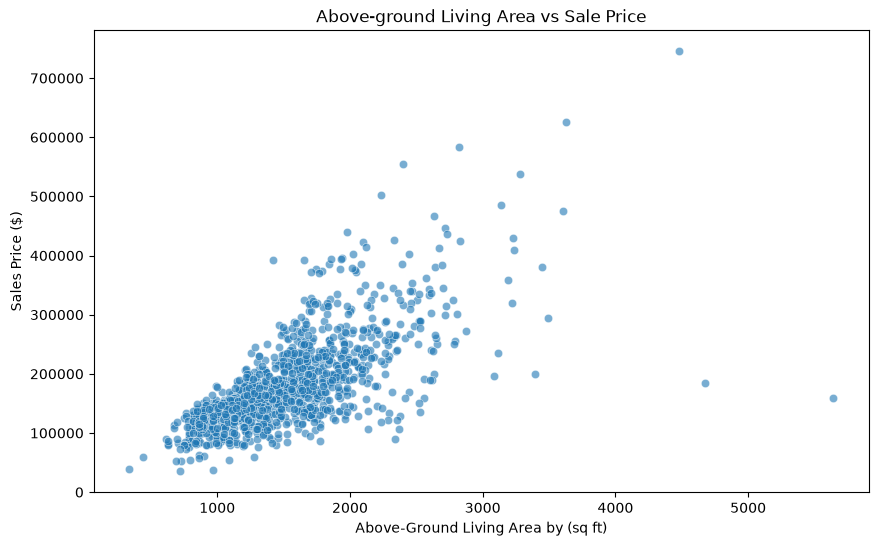

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Explore living area against sale price using training data
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_train["GrLivArea"],
    y=y_train,
    alpha=0.6
)

plt.title("Above-ground Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area by (sq ft)")
plt.ylabel("Sales Price ($)")

## Investigate the Unusual Houses

In [24]:
# Investigate unusually large houses in the training set
candidates = X_train.loc[
    X_train["GrLivArea"] > 4000,
    ["GrLivArea", "OverallQual", "OverallCond", "Neighborhood"]
].copy()

# Retrieve house identifiers and sale prices
candidates["Id"] = df_clean.loc[candidates.index, "Id"]
candidates["SalePrice"] = y_train.loc[candidates.index]

# Calculate sale price per square foot
candidates["PricePerSqFt"] = (
    candidates["SalePrice"] / candidates["GrLivArea"]
)

# Display the largest houses first
display(
    candidates.sort_values("GrLivArea", ascending=False)
)

,GrLivArea,OverallQual,OverallCond,Neighborhood,Id,SalePrice,PricePerSqFt
1298,5642,10,5,Edwards,1299,160000,28.358738
523,4676,10,5,Edwards,524,184750,39.510265
1182,4476,10,5,NoRidge,1183,745000,166.443253


## Investigate Sale Circumstances

In [25]:
# Identify large houses with unusually low prices
outlier_mask = (
    (X_train["GrLivArea"] > 4000) &
    (y_train < 300000)
)

# Inspect additional property and sale details
outlier_details = X_train.loc[
    outlier_mask,
    [
        "GrLivArea",
        "OverallQual",
        "OverallCond",
        "Neighborhood",
        "YearBuilt",
        "SaleType",
        "SaleCondition"
    ]
].copy()

# Retrieve house IDs and actual sale prices
outlier_details["Id"] = df_clean.loc[outlier_details.index, "Id"]
outlier_details["SalePrice"] = y_train.loc[outlier_details.index]

display(outlier_details)

,GrLivArea,OverallQual,OverallCond,Neighborhood,YearBuilt,SaleType,SaleCondition,Id,SalePrice
523,4676,10,5,Edwards,2007,New,Partial,524,184750
1298,5642,10,5,Edwards,2008,New,Partial,1299,160000


## Transforming the Target Variable

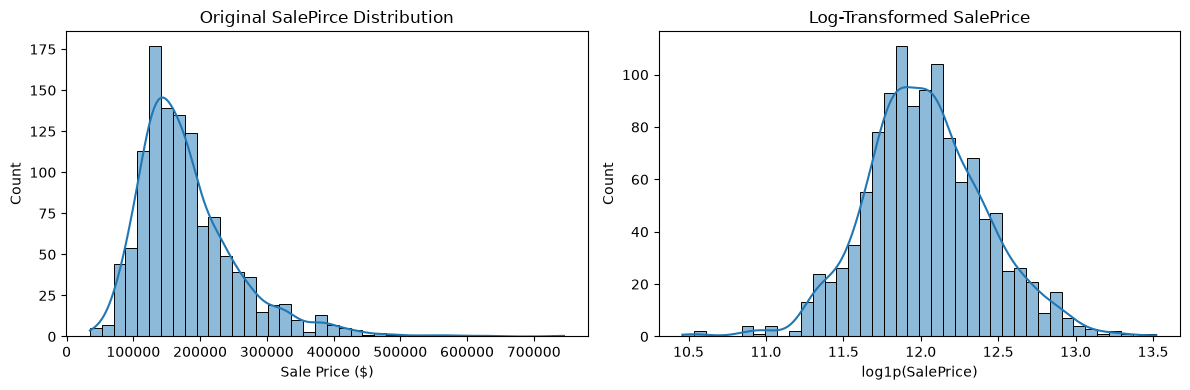

Original skewness: 1.743
Log skewness: 0.125


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Transform the training target
y_train_log = np.log1p(y_train)

# Compare the original and transformed distributions
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.histplot(y_train, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Original SalePirce Distribution")
axes[0].set_xlabel("Sale Price ($)")

sns.histplot(y_train_log, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed SalePrice")
axes[1].set_xlabel("log1p(SalePrice)")

plt.tight_layout()
plt.show()

# Measure the skewness of each distribution
print(f"Original skewness: {y_train.skew():.3f}")
print(f"Log skewness: {y_train_log.skew():.3f}")

## Inspect Actual Categorical Features

In [30]:
# Identify categorical columns in the training data
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns

print("Number of categorical features:", len(categorical_cols))

# Inspect examples of nominal and ordinal features
print("\nNeighborhood categories:")
print(X_train["Neighborhood"].value_counts().head(10))

print("\nExterior quality categories:")
print(X_train["ExterQual"].value_counts(dropna=False))

Number of categorical features: 43

Neighborhood categories:
Neighborhood
NAmes      181
CollgCr    115
OldTown     91
Edwards     87
Somerst     69
NWAmes      66
Gilbert     65
NridgHt     61
Sawyer      58
BrkSide     45
Name: count, dtype: int64

Exterior quality categories:
ExterQual
TA    727
Gd    388
Ex     42
Fa     11
Name: count, dtype: int64


## Implementing One-Hot Encoding

In [31]:
from sklearn.preprocessing import OneHotEncoder

# Initialize the encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Encode neighborhoods using training data
encoded = encoder.fit_transform(
    X_train[["Neighborhood"]]
)

# Convert the result into a readable DataFrame
encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(),
    index=X_train.index
)

print("Original shape:", X_train[["Neighborhood"]].shape)
print("Encoded shape:", encoded_df.shape)

display(encoded_df.head())

Original shape: (1168, 1)
Encoded shape: (1168, 25)


,Neighborhood_Blmngtn,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,...,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker
254,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1066,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
638,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
799,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
380,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## Ordinal Encoding

In [32]:
# Define the quality ranking
quality_order = {
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

# Encode exterior quality without modifying X_train
encoded_quality = X_train["ExterQual"].map(quality_order)

# Compare original and encoded values
comparison = pd.DataFrame({
    "Original": X_train["ExterQual"],
    "Encoded": encoded_quality
})

display(comparison.head(10))

# Verify the encoding
print("Unmapped values:", encoded_quality.isna().sum())

,Original,Encoded
254,TA,3
1066,Gd,4
638,TA,3
799,TA,3
380,TA,3
303,TA,3
86,Gd,4
1385,TA,3
265,TA,3
793,Gd,4


Unmapped values: 0
